# 02 — Exploratory Data Analysis

## Objective

This notebook explores the relationships between customer characteristics and churn.

The goal is to identify patterns, associations, and customer segments that may be useful for subsequent machine learning modeling.

The analysis focuses on:

- churn distribution;
- contract characteristics;
- customer tenure;
- billing variables;
- internet and support services;
- payment methods;
- differences between churned and retained customers.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

In [2]:
PROJECT_ROOT = Path("..")
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "WA_FnUseC_TelcoCustomerChurn.csv"

df = pd.read_csv(DATA_PATH)

In [3]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

## 1. Target distribution

Understanding the class distribution is important before analyzing the relationship between churn and the explanatory variables.

In [4]:
churn_counts = df["Churn"].value_counts()
churn_rates = df["Churn"].value_counts(normalize=True) * 100

pd.DataFrame({
    "count": churn_counts,
    "percentage": churn_rates
})

,count,percentage
Churn,,
No,5174,73.463013
Yes,1869,26.536987


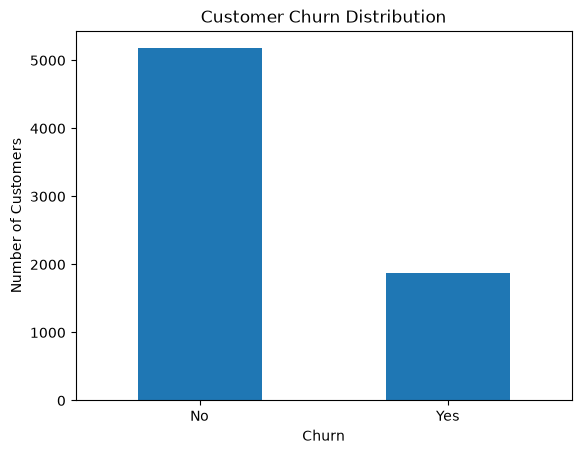

In [5]:
churn_counts.plot(kind="bar")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

## 2. Churn by contract type

Contract duration may be associated with customer retention because longer-term contracts may reflect stronger customer commitment.

In [6]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

contract_churn

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


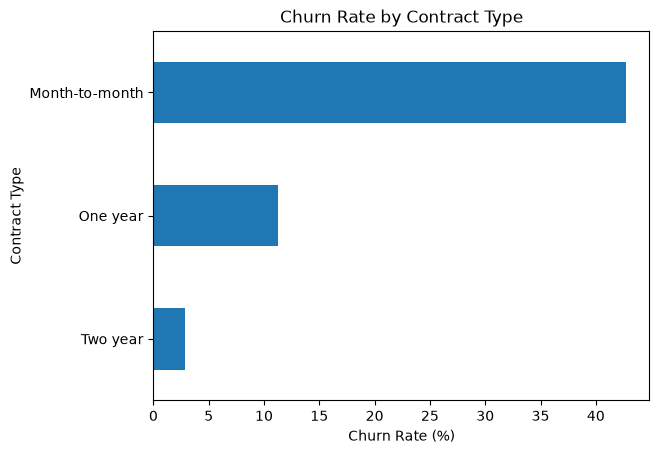

In [7]:
contract_churn["Yes"].sort_values().plot(kind="barh")

plt.title("Churn Rate by Contract Type")
plt.xlabel("Churn Rate (%)")
plt.ylabel("Contract Type")
plt.show()

## 3. Churn and customer tenure

Customer tenure may capture customer loyalty or the maturity of the relationship with the company.

In [8]:
df.groupby("Churn")["tenure"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
Churn,,,,,
No,5174,37.569965,38.0,0,72
Yes,1869,17.979133,10.0,1,72


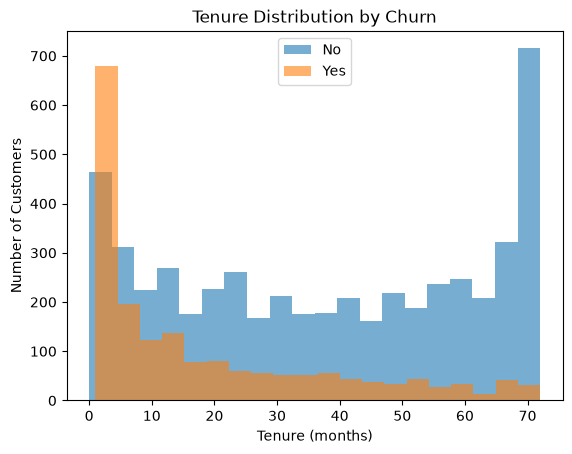

In [9]:
df.loc[df["Churn"] == "No", "tenure"].plot(
    kind="hist",
    bins=20,
    alpha=0.6,
    label="No"
)

df.loc[df["Churn"] == "Yes", "tenure"].plot(
    kind="hist",
    bins=20,
    alpha=0.6,
    label="Yes"
)

plt.title("Tenure Distribution by Churn")
plt.xlabel("Tenure (months)")
plt.ylabel("Number of Customers")
plt.legend()
plt.show()

## 4. Churn and monthly charges

Monthly pricing may be associated with churn because customers with higher recurring costs may be more sensitive to perceived value.

In [10]:
df.groupby("Churn")["MonthlyCharges"].agg(
    ["mean", "median", "std", "min", "max"]
)

,mean,median,std,min,max
Churn,,,,,
No,61.265124,64.425,31.092648,18.25,118.75
Yes,74.441332,79.650,24.666053,18.85,118.35


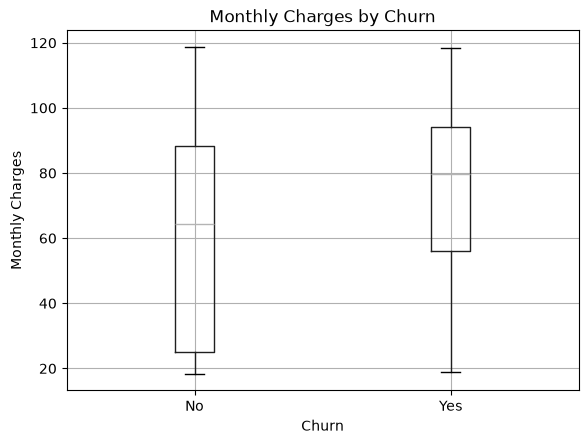

In [11]:
df.boxplot(
    column="MonthlyCharges",
    by="Churn"
)

plt.title("Monthly Charges by Churn")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.show()

## 5. Churn by internet service

Internet service type may be associated with churn because different technologies, prices, or service experiences can affect customer retention.

In [12]:
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

internet_churn

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


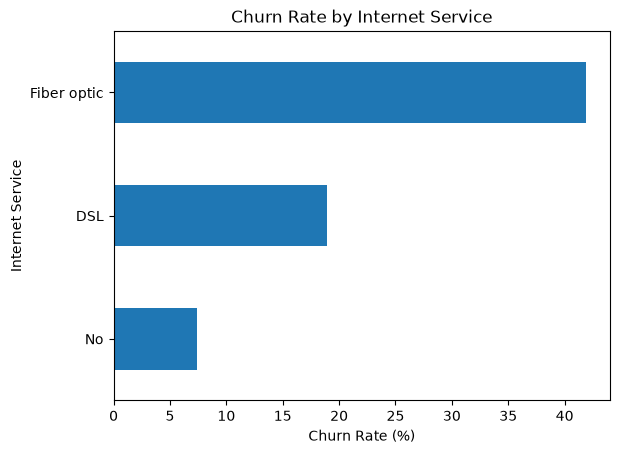

In [13]:
internet_churn["Yes"].sort_values().plot(kind="barh")

plt.title("Churn Rate by Internet Service")
plt.xlabel("Churn Rate (%)")
plt.ylabel("Internet Service")
plt.show()

## 6. Churn by payment method

Payment method may capture differences in customer behavior, convenience, commitment, or billing experience.

In [14]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

payment_churn

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


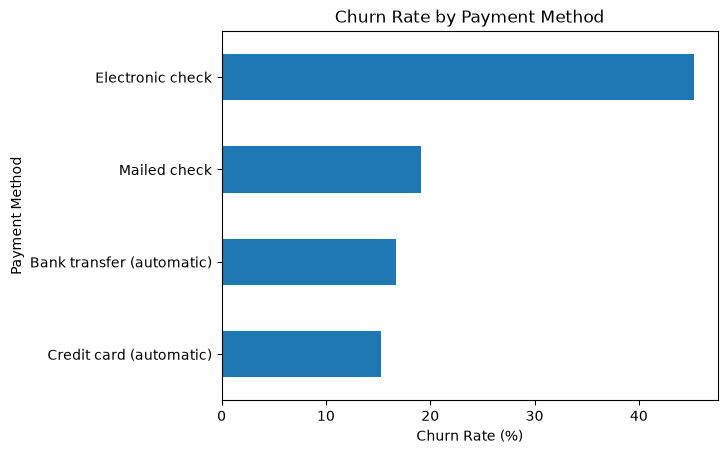

In [15]:
payment_churn["Yes"].sort_values().plot(kind="barh")

plt.title("Churn Rate by Payment Method")
plt.xlabel("Churn Rate (%)")
plt.ylabel("Payment Method")
plt.show()

## 7. Churn by support and security services

Additional support and security services may be associated with customer retention because they can increase product value and customer engagement.

In [16]:
security_churn = pd.crosstab(
    df["OnlineSecurity"],
    df["Churn"],
    normalize="index"
) * 100

security_churn

Churn,No,Yes
OnlineSecurity,,
No,58.233276,41.766724
No internet service,92.595020,7.404980
Yes,85.388806,14.611194


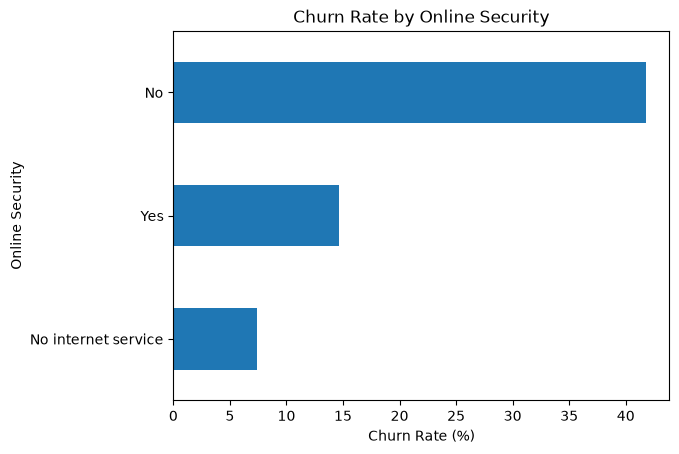

In [17]:
security_churn["Yes"].sort_values().plot(kind="barh")

plt.title("Churn Rate by Online Security")
plt.xlabel("Churn Rate (%)")
plt.ylabel("Online Security")
plt.show()

In [18]:
support_churn = pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index"
) * 100

support_churn

Churn,No,Yes
TechSupport,,
No,58.364526,41.635474
No internet service,92.595020,7.404980
Yes,84.833659,15.166341


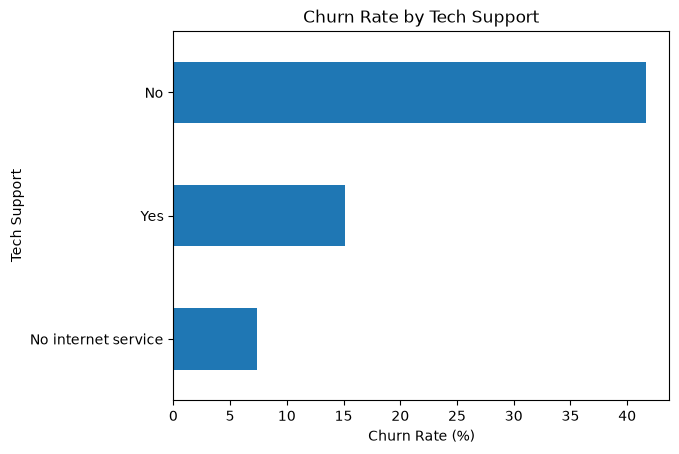

In [19]:
support_churn["Yes"].sort_values().plot(kind="barh")

plt.title("Churn Rate by Tech Support")
plt.xlabel("Churn Rate (%)")
plt.ylabel("Tech Support")
plt.show()

In [20]:
def churn_rate_by(column):
    return (
        pd.crosstab(
            df[column],
            df["Churn"],
            normalize="index"
        )["Yes"]
        .mul(100)
        .sort_values()
    )

In [21]:
service_columns = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

In [22]:
for column in service_columns:
    print(f"\n--- {column} ---")
    print(churn_rate_by(column))


--- OnlineSecurity ---
OnlineSecurity
No internet service     7.404980
Yes                    14.611194
No                     41.766724
Name: Yes, dtype: float64

--- OnlineBackup ---
OnlineBackup
No internet service     7.404980
Yes                    21.531494
No                     39.928756
Name: Yes, dtype: float64

--- DeviceProtection ---
DeviceProtection
No internet service     7.404980
Yes                    22.502064
No                     39.127625
Name: Yes, dtype: float64

--- TechSupport ---
TechSupport
No internet service     7.404980
Yes                    15.166341
No                     41.635474
Name: Yes, dtype: float64

--- StreamingTV ---
StreamingTV
No internet service     7.404980
Yes                    30.070188
No                     33.523132
Name: Yes, dtype: float64

--- StreamingMovies ---
StreamingMovies
No internet service     7.404980
Yes                    29.941435
No                     33.680431
Name: Yes, dtype: float64


## 8. Churn and total charges

`TotalCharges` represents the cumulative amount charged to a customer.

Its relationship with churn must be interpreted together with tenure, since customers who have stayed longer naturally tend to accumulate higher total charges.

In [23]:
df.groupby("Churn")["TotalCharges"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

,count,mean,median,std,min,max
Churn,,,,,,
No,5163,2555.344141,1683.60,2329.456984,18.80,8672.45
Yes,1869,1531.796094,703.55,1890.822994,18.85,8684.80


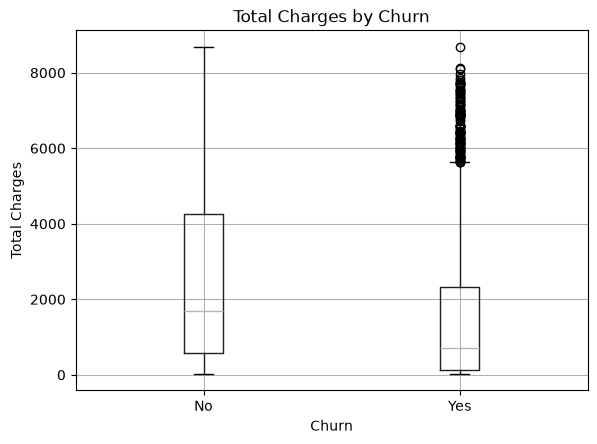

In [24]:
df.boxplot(
    column="TotalCharges",
    by="Churn"
)

plt.title("Total Charges by Churn")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Total Charges")
plt.show()

In [25]:
tenure_bins = pd.cut(
    df["tenure"],
    bins=[-1, 6, 12, 24, 48, 72],
    labels=[
        "0-6 months",
        "7-12 months",
        "13-24 months",
        "25-48 months",
        "49-72 months"
    ]
)

In [26]:
pd.crosstab(
    tenure_bins,
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
tenure,,
0-6 months,47.062795,52.937205
7-12 months,64.113475,35.886525
13-24 months,71.289062,28.710938
25-48 months,79.611041,20.388959
49-72 months,90.486824,9.513176


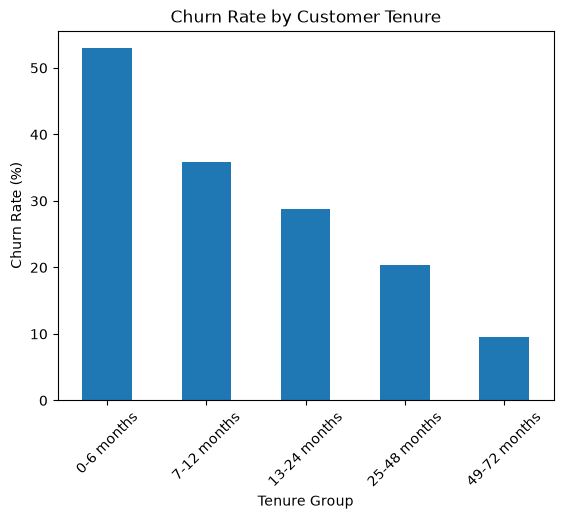

In [27]:
tenure_churn_rate = (
    pd.crosstab(
        tenure_bins,
        df["Churn"],
        normalize="index"
    )["Yes"] * 100
)

tenure_churn_rate.plot(kind="bar")

plt.title("Churn Rate by Customer Tenure")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=45)
plt.show()

## 9. Interaction between contract type and payment method

Payment method showed a notable association with churn. However, this relationship may be influenced by contract type.

This section explores whether churn differences across payment methods remain similar within different contract categories.

In [28]:
contract_payment_churn = (
    df.groupby(["Contract", "PaymentMethod"])["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .unstack()
)

contract_payment_churn

PaymentMethod,Bank transfer (automatic),Credit card (automatic),Electronic check,Mailed check
Contract,,,,
Month-to-month,34.125637,32.780847,53.729730,31.578947
One year,9.718670,10.301508,18.443804,6.824926
Two year,3.368794,2.237522,7.738095,0.785340


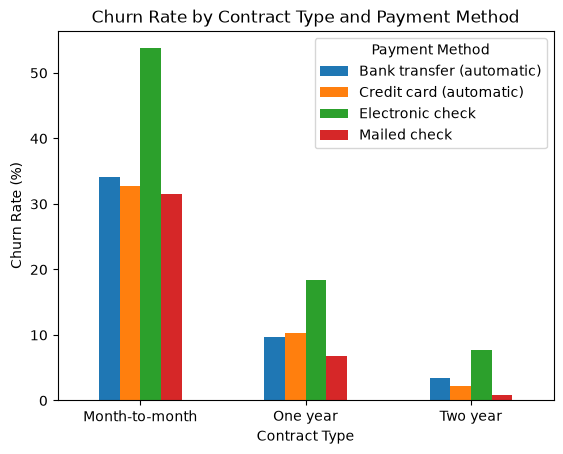

In [29]:
contract_payment_churn.plot(kind="bar")

plt.title("Churn Rate by Contract Type and Payment Method")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.legend(title="Payment Method")
plt.show()

## 10. Interaction between tenure and contract type

Tenure and contract type both showed strong associations with churn. This section explores how both variables behave together.

In [30]:
tenure_contract_churn = (
    df.assign(tenure_group=tenure_bins)
    .groupby(["tenure_group", "Contract"], observed=False)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .unstack()
)

tenure_contract_churn

Contract,Month-to-month,One year,Two year
tenure_group,,,
0-6 months,55.201699,10.256410,0.000000
7-12 months,41.996558,10.588235,0.000000
13-24 months,37.720488,8.121827,0.000000
25-48 months,32.917706,10.617761,2.189781
49-72 months,26.023392,12.933754,3.325416


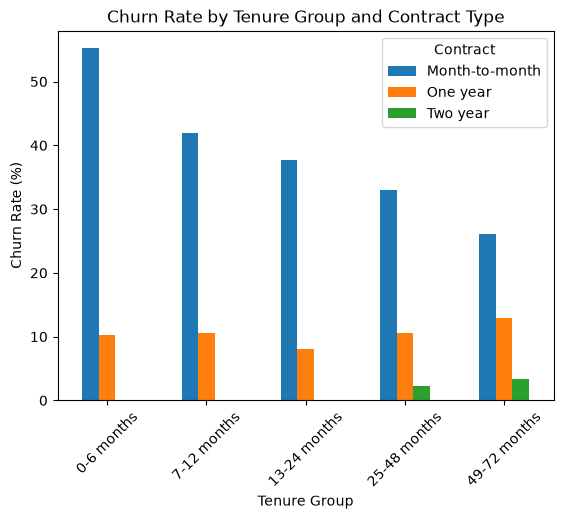

In [31]:
tenure_contract_churn.plot(kind="bar")

plt.title("Churn Rate by Tenure Group and Contract Type")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=45)
plt.legend(title="Contract")
plt.show()

## 11. Numerical comparison by churn status

The main numerical variables are compared between churned and retained customers to summarize the differences observed during the exploratory analysis.

In [32]:
numerical_summary = (
    df.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]]
    .agg(["mean", "median", "std"])
)

numerical_summary

tenure                   MonthlyCharges                     \
            mean median        std           mean  median        std   
Churn                                                                  
No     37.569965   38.0  24.113777      61.265124  64.425  31.092648   
Yes    17.979133   10.0  19.531123      74.441332  79.650  24.666053   

      TotalCharges                        
              mean   median          std  
Churn                                     
No     2555.344141  1683.60  2329.456984  
Yes    1531.796094   703.55  1890.822994

## Key findings

The exploratory analysis identified several notable patterns associated with customer churn:

- Customers with month-to-month contracts show substantially higher churn rates than customers with one-year or two-year contracts.
- Churn is considerably more common among customers with shorter tenure.
- Customers who churn tend to have higher monthly charges, although the distributions overlap substantially.
- Fiber optic internet customers show a higher churn rate than other internet service groups.
- Electronic check users show a relatively high churn rate, although this relationship should be interpreted together with contract type.
- Customers without online security or technical support show higher churn rates than customers using these services.
- Lower `TotalCharges` among churned customers appears to be strongly related to their shorter tenure rather than necessarily indicating a direct effect of total spending.
- The combination of tenure and contract type suggests that recently acquired month-to-month customers may represent a particularly high-risk segment.

These findings describe associations in the observed dataset and should not be interpreted as causal relationships.

## Modeling hypotheses

The exploratory analysis suggests several hypotheses to evaluate during modeling:

1. `Contract` and `tenure` are likely to be among the strongest predictors of churn.
2. `MonthlyCharges`, `InternetService`, `PaymentMethod`, `OnlineSecurity`, and `TechSupport` may provide additional predictive information.
3. Some variables may interact with each other, particularly contract type, tenure, and payment behavior.
4. Customer identifiers should be excluded from predictive modeling.
5. Model evaluation should account for the moderate class imbalance observed in the target variable.

The next stage will build a reproducible preprocessing pipeline and establish baseline classification models.